# Proposal 1 + SR discrepancy (Dataset 2)

# Libraries

In [1]:
import json
import re
import unicodedata
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams.update({
                        'font.family': 'serif',
                        'mathtext.fontset': 'cm',
                        'axes.unicode_minus': False
                    })
import numpy as np
import pandas as pd
import seaborn as sns
import scipy as sci
from sklearn.metrics import r2_score

# Dataset upload and computing error model

In [2]:
def clean_column_name(name):
    name = unicodedata.normalize('NFKD', str(name)).encode('ASCII', 'ignore').decode('ASCII')
    name = name.lower()
    name = name.replace(' ', '_')
    name = re.sub(r'[^\w_]', '', name)
    name = re.sub(r'__+', '_', name)
    name = name.strip('_')
    return name

data = pd.read_excel('../../dataset/dataset_2_rv3.xlsx')
data.columns = [clean_column_name(col) for col in data.columns]
data['w_exp'] = data['output_w_exp_mm']
data['w_ref'] = data['fib_model_code_2020_com_ts_variavel_mm']

### PySR discrepancy model

The adopted model (index, equation, complexity, score and z-score parameters) is exported by `train_symbolic_regression/fib2020ts-dataset2/inspect_psr_results.ipynb`.

In [3]:
with open('../../train_symbolic_regression/fib2020ts-dataset2/selected_model.json', 'r', encoding='utf-8') as f:
    selected = json.load(f)
print(f"Index: {selected['index']} | complexity: {selected['complexity']} | score: {selected['score']:.4f}")
print(f"R2 train: {selected['train_r2']:.3f} | R2 test: {selected['test_r2']:.3f}")
print(f"w = {selected['latex']}")

Index: 79 | complexity: 18 | score: 0.0772
R2 train: 0.687 | R2 test: 0.771
w = \left(- 0.103875965 w_{ec} + 0.075556934 w_{yuan} - 0.103875965 \left(\sigma_{sts} - w_{caldas}\right) \cos{\left(f_{t} \right)}\right) \cos{\left(\sin{\left(cob \right)} \right)}


In [4]:
def computing_equation(df, selected):
    # Z-score the inputs with the training-set parameters and evaluate the PySR expression
    env = {
            'sin': np.sin, 'cos': np.cos, 'exp': np.exp, 'abs': np.abs, 'sqrt': np.sqrt, 'log': np.log,
            'square': np.square, 'cube': lambda x: x ** 3,
          }
    for col, par in selected['scaler'].items():
        env[col] = (df[col] - par['avg']) / par['std_dev'] if par['std_dev'] != 0 else 0.0
    return eval(selected['equation'], env)

data['error'] = computing_equation(data, selected)
data['wnum'] = data['w_ref'] + data['error']

In [5]:
data['wnum/wexp'] = data['wnum'] / data['w_exp']
data[['w_exp', 'w_ref', 'wnum', 'wnum/wexp']].describe()

,w_exp,w_ref,wnum,wnum/wexp
count,341.000000,341.000000,341.000000,341.000000
mean,0.261672,0.266323,0.264597,1.044978
std,0.115072,0.117894,0.103342,0.194755
min,0.140000,0.052197,0.123697,0.615440
25%,0.190000,0.178993,0.201685,0.895016
50%,0.230000,0.250469,0.240633,1.034379
75%,0.300000,0.330521,0.286817,1.187259
max,0.790000,0.701453,0.716604,1.735849


In [6]:
data.to_excel('statistics_pysr_dataset2ts_results.xlsx', index=False)

### Metrics

In [7]:
obs = data['w_exp']
pred = data['wnum']
ratio = data['wnum/wexp']
big = obs > 0.4
r2_model = r2_score(obs, pred)
print(f"R2                     = {r2_model:.3f}")
print(f"RMSE (mm)              = {np.sqrt(np.mean((pred - obs) ** 2)):.3f}")
print(f"Mean bias (mm)         = {np.mean(pred - obs):.3f}")
print(f"Mean wnum/wexp         = {ratio.mean():.3f}")
print(f"Std wnum/wexp          = {ratio.std():.3f}")
print(f"CoV wnum/wexp          = {ratio.std() / ratio.mean():.3f}")
print(f"w_exp > 0.4 mm (n={big.sum()}): mean wnum/wexp = {ratio[big].mean():.3f}, mean bias (mm) = {np.mean((pred - obs)[big]):.3f}")

R2                     = 0.820
RMSE (mm)              = 0.049
Mean bias (mm)         = 0.003
Mean wnum/wexp         = 1.045
Std wnum/wexp          = 0.195
CoV wnum/wexp          = 0.186
w_exp > 0.4 mm (n=30): mean wnum/wexp = 0.929, mean bias (mm) = -0.039


# Charts

In [8]:
name = 'fib_model_2020ts-pysr-model-dataset-2-8020'

### Predict versus Experimental

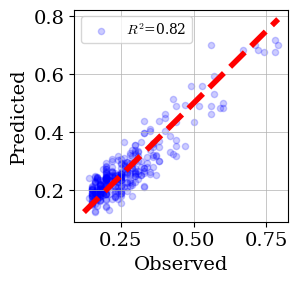

In [9]:
dpi = 600
b_cm = 7
h_cm = 7
inches_to_cm = 1 / 2.54
b_input = b_cm * inches_to_cm
h_input = h_cm * inches_to_cm
fig, ax = plt.subplots(figsize=(b_input, h_input))
lims = [min(data['w_exp'].min(), data['wnum'].min()), max(data['w_exp'].max(), data['wnum'].max())]
ax.tick_params(axis='both', which='major', labelsize=14, colors='black')
ax.set_xlabel('Observed', fontsize=14, color='black')
ax.set_ylabel('Predicted', fontsize=14, color='black')
plt.grid(True, which='both', linestyle='-', linewidth=0.5)
ax.plot(lims, lims, linewidth=4, linestyle='--', color='red')
ax.scatter(data['w_exp'], data['wnum'], alpha=0.2, color='blue', s=20, label=rf'$R^2$={r2_model:.2f}')
ax.legend(fontsize=10, loc='upper left')
fig.savefig(f'z_scatter-line_{name}.png', dpi=dpi, bbox_inches='tight')
plt.show()

### KDE

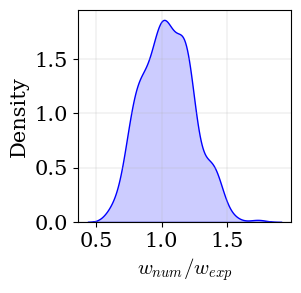

In [10]:
label_x = '$w_{num}/w_{exp}$'
fig, ax = plt.subplots(figsize=(b_input, h_input))
ax.tick_params(axis='both', which='major', labelsize=15, colors='black')
ax.set_xlabel(label_x, fontsize=15, color='black')
ax.set_ylabel('Density', fontsize=15, color='black')
plt.grid(True, which='both', linestyle='-', linewidth=0.2)
sns.kdeplot(data=data, x='wnum/wexp', fill=True, alpha=0.2, color='blue', ax=ax)
fig.savefig(f'z_kde_{name}.png', dpi=dpi, bbox_inches='tight')
plt.show()

# Goodness-of-fit

### Kolmogorov-Smirnov test

In [11]:
x = data['wnum/wexp'].values
for dist_name in ['norm', 't', 'lognorm']:
    dist = getattr(sci.stats, dist_name)
    params = dist.fit(x)
    ks_stat, ks_p = sci.stats.kstest(x, dist.cdf, args=params)
    print(f"{dist_name:8s} KS statistic = {ks_stat:.4f} | p-value = {ks_p:.4f} | parameters = {np.round(params, 4)}")

norm     KS statistic = 0.0429 | p-value = 0.5430 | parameters = [1.045  0.1945]
t        KS statistic = 0.0429 | p-value = 0.5430 | parameters = [2.85405923e+09 1.04500000e+00 1.94500000e-01]
lognorm  KS statistic = 0.0398 | p-value = 0.6389 | parameters = [ 0.1027 -0.8467  1.8817]


### Lognormal fit versus original data

shape = 0.1848
scale = 1.0273


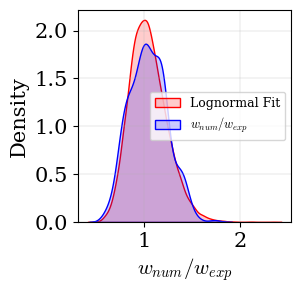

In [12]:
mean = data['wnum/wexp'].mean()
std = data['wnum/wexp'].std()
sigma = np.sqrt(np.log(1 + (std / mean) ** 2))
mu = np.log(mean) - 0.5 * sigma ** 2
print(f"shape = {sigma:.4f}")
print(f"scale = {np.exp(mu):.4f}")
synthetic_data = sci.stats.lognorm.rvs(s=sigma, loc=0.0, scale=np.exp(mu), size=20000, random_state=42)

fig, ax = plt.subplots(figsize=(b_input, h_input))
ax.tick_params(axis='both', which='major', labelsize=15, colors='black')
ax.set_xlabel(label_x, fontsize=15, color='black')
ax.set_ylabel('Density', fontsize=15, color='black')
plt.grid(True, which='both', linestyle='-', linewidth=0.2)
sns.kdeplot(data=synthetic_data, fill=True, alpha=0.2, color='red', label='Lognormal Fit', ax=ax)
sns.kdeplot(data=list(data['wnum/wexp']), fill=True, alpha=0.2, color='blue', label='$w_{num}/w_{exp}$', ax=ax)
ax.legend(fontsize=9, loc='center right')
fig.savefig(f'z_kde_{name}_gt_versus_lognormal.png', dpi=dpi, bbox_inches='tight')
plt.show()